# Summary of Insights
## Sentiment and Topic Trajectories Across Crisis Phases

This notebook consolidates findings from sentiment analysis, topic modeling, and cross-phase analysis into a single narrative summary. It covers:

1. **Sentiment Trajectory Across Phases** — how polarity and negativity evolve chronologically
2. **Phases Ranked by Negativity** — which crisis events provoked the most negative response
3. **Day 1 vs Rest: Within-Phase Outrage Decay** — whether initial outrage decays or sustains within each phase
4. **Topics Per Phase** — dominant topics per phase and their sentiment valence
5. **Topic Trajectory Across Phases** — how topics persist or shift across phase boundaries
6. **Additional Analyses** — phase boundary sentiment shifts

## Setup
Import dependencies, configure paths, and define phase constants.

In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, kendalltau

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 5)

SEED = 42
np.random.seed(SEED)

crisis_name = "ateneo-drowning"  # overridden by papermill
OUTPUT_DIR = Path(f"../../02-analysis/output/{crisis_name}")
YT_SENTIMENT_DIR = OUTPUT_DIR / "youtube-comments" / "sentiment-analysis"
YT_TOPICS_DIR = OUTPUT_DIR / "youtube-comments" / "topic-modeling"
FIGURES_DIR = Path("../../outputs/figures/03-insights")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PHASE_ORDER = [
    "01-onset",
    "02-confirmation",
    "03-spread",
    "04-reckoning",
    "05-lingering",
]

PHASE_LABELS = [
    "Onset",
    "Confirmation",
    "Spread",
    "Reckoning",
    "Lingering",
]

PHASE_DISPLAY = dict(zip(PHASE_ORDER, PHASE_LABELS))

### Crisis Event Timeline
Reference table anchoring each phase to actual news events.

In [22]:
EVENT_TIMELINE = [
    ("01-onset",          "Jun 8",  "Drowning incident; Ateneo confirms deaths"),
    ("02-confirmation",   "Jun 9",  "Autopsy requested; public outcry begins"),
    ("03-spread",         "Jun 11", "Viral rumors; public outcry; podcast debate"),
    ("04-reckoning",      "Jun 15", "Baldwin resignation; Fr. Yap statement; UAAP ban"),
    ("05-lingering",      "Jun 19", "CIDG/NBI hearings; legal proceedings"),
]

EVENT_DATES = pd.DataFrame(EVENT_TIMELINE, columns=["phase", "event_date_str", "event_description"])
EVENT_DATES["event_date_num"] = pd.to_datetime(EVENT_DATES["event_date_str"], format="%b %d")
phase_boundaries = EVENT_DATES.copy()
phase_boundaries["label"] = phase_boundaries["phase"].map(PHASE_DISPLAY)

print("Phase boundary dates:")
for _, row in phase_boundaries.iterrows():
    print(f"  {row['event_date_str']:12s} | {row['label']:25s} | {row['event_description']}")

Phase boundary dates:
  Jun 8        | The Incident              | Drowning incident; Ateneo confirms deaths
  Jun 9        | Autopsy Request           | Family requests autopsy; NBI/CIDG coordinate
  Jun 11       | Public Outcry             | Viral rumors: ankle weights, hazing
  Jun 12       | Baldwin Apology           | Baldwin video apology; remains arrive
  Jun 14       | Scholarships Withdrawn    | Scholarships offered; Filoil withdrawal
  Jun 15       | Resignation Press Con     | Fr. Yap accepts Baldwin's resignation
  Jun 16       | Townhall Podcast          | Team captain townhall; podcast interviews
  Jun 19       | UAAP Ban                  | UAAP bans coaching staff
  Jun 19       | Legal Probe               | CIDG/NBI hearings; hazing investigation


## Load & Merge Data
Load all scored sentiment files and topic-modeled CSVs, merging into a single DataFrame.

In [23]:
frames = []
for phase in PHASE_ORDER:
    path = YT_SENTIMENT_DIR / f"scored_{phase}.csv"
    if not path.exists():
        print(f"WARNING: {path.name} not found -- skipping")
        continue
    df_batch = pd.read_csv(path, parse_dates=["create_time"])
    df_batch["phase"] = phase
    df_batch["phase_label"] = PHASE_DISPLAY[phase]
    frames.append(df_batch)

df_sentiment = pd.concat(frames, ignore_index=True)
print(f"Loaded sentiment data: {len(df_sentiment):,} comments across {df_sentiment['phase'].nunique()} phases")

Loaded sentiment data: 10,607 comments across 9 phases


In [24]:
topic_frames = []
for path in sorted(YT_TOPICS_DIR.glob("topics_*.csv")):
    tt = pd.read_csv(path)
    phase = path.stem.replace("topics_", "")
    tt["phase"] = phase
    topic_frames.append(tt)

df_topics = pd.concat(topic_frames, ignore_index=True)
topic_cols = [c for c in df_topics.columns if c in ("topic_id", "topic_label")]
keep_cols = ["text", "phase"] + topic_cols
keep_cols = [c for c in keep_cols if c in df_topics.columns]
df_topics_sub = df_topics[keep_cols].copy()

df = df_sentiment.merge(df_topics_sub, on=["text", "phase"], how="left", suffixes=("", "_topic"))

print(f"Merged DataFrame: {len(df):,} rows, {len(df.columns)} columns")
print(f"Columns: {list(df.columns)}")

Merged DataFrame: 10,607 rows, 12 columns
Columns: ['video_id', 'text', 'like_count', 'create_time', 'is_shouting', 'sentences', 'sentiment_label', 'sentiment_score', 'phase', 'phase_label', 'topic_id', 'topic_label']


In [25]:
print(f"Rows with missing sentiment_label: {df['sentiment_label'].isna().sum()}")
print(f"Rows with missing topic_label: {df['topic_label'].isna().sum()}")
print()
print(f"Timestamp range: {df['create_time'].min()} to {df['create_time'].max()}")
print(f"Unique dates: {df['create_time'].dt.date.nunique()}")
print()
print("Comments per phase:")
for p in PHASE_ORDER:
    n = (df['phase'] == p).sum()
    if n > 0:
        print(f"  {PHASE_DISPLAY[p]:35s} {n:5,}")

Rows with missing sentiment_label: 2
Rows with missing topic_label: 3382

Timestamp range: 2026-06-10 00:00:00+00:00 to 2026-06-24 04:19:00+00:00
Unique dates: 15

Comments per phase:
  The Incident                          857
  Autopsy Request                     2,399
  Public Outcry                         254
  Baldwin Apology                       752
  Scholarships Withdrawn                542
  Resignation Press Con                 309
  Townhall Podcast                    5,135
  UAAP Ban                              100
  Legal Probe                           259


> **Note on missing topic labels:** BERTopic's HDBSCAN clustering assigned
> 31.9% of comments (3,382 rows) to the noise cluster (`topic_id = -1`).
> These comments did not form dense enough clusters for coherent topic assignment.
> All topic-per-phase analyses reflect only the 68.1% of comments with assigned topics.
> This noise rate is within normal range for BERTopic on informal code-switched
> social media text.

---
## 1. Sentiment Trajectory Across Phases

How does public sentiment evolve as the crisis unfolds? We aggregate sentiment per phase and plot the **Polarity Index** (%positive − %negative) in chronological order. A more negative value means more outrage relative to positive sentiment. We also compute a **Mann-Kendall trend test** to check if polarity shows a monotonic trend over time.

In [26]:
phase_agg = (
    df.groupby("phase")
    .agg(
        total_comments=("sentiment_label", "count"),
        n_negative=("sentiment_label", lambda x: (x == "NEGATIVE").sum()),
        n_positive=("sentiment_label", lambda x: (x == "POSITIVE").sum()),
        n_neutral=("sentiment_label", lambda x: (x == "NEUTRAL").sum()),
        mean_likes=("like_count", "mean"),
    )
    .reset_index()
)

phase_agg["pct_negative"] = phase_agg["n_negative"] / phase_agg["total_comments"] * 100
phase_agg["pct_positive"] = phase_agg["n_positive"] / phase_agg["total_comments"] * 100
phase_agg["pct_neutral"] = phase_agg["n_neutral"] / phase_agg["total_comments"] * 100
phase_agg["polarity_index"] = phase_agg["pct_positive"] - phase_agg["pct_negative"]
phase_agg["label"] = phase_agg["phase"].map(PHASE_DISPLAY)
phase_agg["event_date"] = phase_agg["phase"].map(
    dict(zip(EVENT_DATES["phase"], EVENT_DATES["event_date_str"]))
)

phase_agg["phase_num"] = phase_agg["phase"].map(
    {p: i for i, p in enumerate(PHASE_ORDER)}
)
phase_agg = phase_agg.sort_values("phase_num").reset_index(drop=True)

print("Sentiment per phase (sorted chronologically):")
display(phase_agg[["label", "event_date", "total_comments",
                    "pct_negative", "pct_positive", "pct_neutral",
                    "polarity_index", "mean_likes"]].round(1))

Sentiment per phase (sorted chronologically):


,label,event_date,total_comments,pct_negative,pct_positive,pct_neutral,polarity_index,mean_likes
0,The Incident,Jun 8,857,71.5,5.0,23.5,-66.5,2.4
1,Autopsy Request,Jun 9,2399,77.9,3.8,18.3,-74.2,1.9
2,Public Outcry,Jun 11,254,67.7,10.6,21.7,-57.1,1.0
3,Baldwin Apology,Jun 12,752,77.1,6.6,16.2,-70.5,2.2
4,Scholarships Withdrawn,Jun 14,542,58.7,16.8,24.5,-41.9,2.7
5,Resignation Press Con,Jun 15,309,79.0,4.5,16.5,-74.4,2.1
6,Townhall Podcast,Jun 16,5134,73.5,7.4,19.0,-66.1,3.6
7,UAAP Ban,Jun 19,100,53.0,32.0,15.0,-21.0,3.0
8,Legal Probe,Jun 19,258,72.9,7.0,20.2,-65.9,1.4


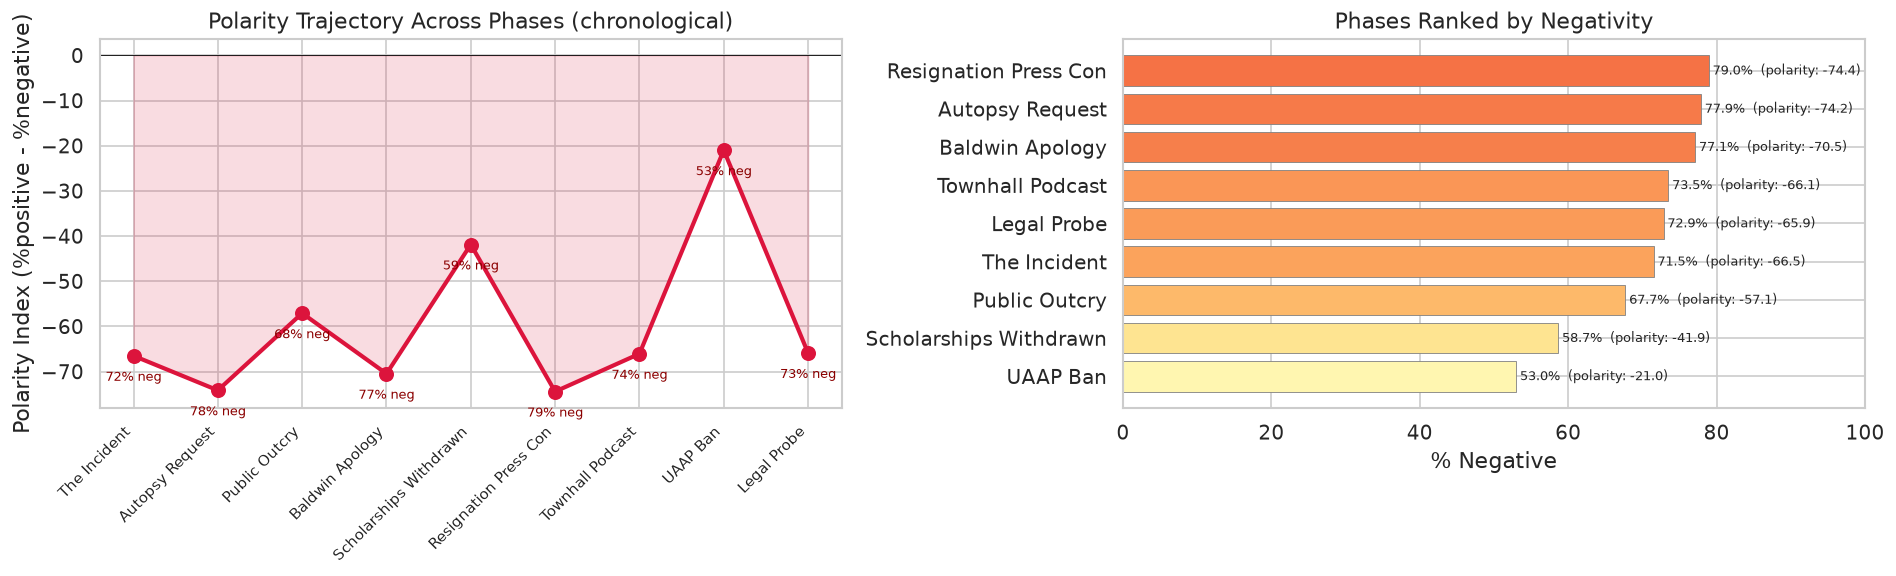

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(phase_agg))
ax1.plot(x, phase_agg["polarity_index"], color="crimson", linewidth=2.5,
         marker="o", markersize=8, zorder=3)
ax1.fill_between(x, phase_agg["polarity_index"], 0,
                 where=(phase_agg["polarity_index"] < 0),
                 color="crimson", alpha=0.15)
ax1.axhline(y=0, color="black", linewidth=0.5)
ax1.set_xticks(x)
ax1.set_xticklabels(phase_agg["label"], rotation=45, ha="right", fontsize=9)
ax1.set_ylabel("Polarity Index (%positive - %negative)")
ax1.set_title("Polarity Trajectory Across Phases (chronological)")

for _, row in phase_agg.iterrows():
    ax1.annotate(f"{row['pct_negative']:.0f}% neg",
                 (row["phase_num"], row["polarity_index"]),
                 textcoords="offset points", xytext=(0, -15),
                 ha="center", fontsize=8, color="darkred")

phase_sorted = phase_agg.sort_values("pct_negative", ascending=True)
colors = plt.cm.RdYlGn_r(phase_sorted["pct_negative"] / 100)
bars = ax2.barh(phase_sorted["label"], phase_sorted["pct_negative"],
                color=colors, edgecolor="gray", linewidth=0.5)

for bar, val, pol in zip(bars, phase_sorted["pct_negative"], phase_sorted["polarity_index"]):
    ax2.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
             f"{val:.1f}%  (polarity: {pol:.1f})",
             va="center", fontsize=8)

ax2.set_xlabel("% Negative")
ax2.set_title("Phases Ranked by Negativity")
ax2.set_xlim(0, 100)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary_phase_sentiment_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
most_neg = phase_agg.loc[phase_agg["pct_negative"].idxmax()]
least_neg = phase_agg.loc[phase_agg["pct_negative"].idxmin()]

print(f"Most negative phase:  {most_neg['label']}  ({most_neg['pct_negative']:.1f}% negative, "
      f"polarity {most_neg['polarity_index']:.1f})")
print(f"Least negative phase: {least_neg['label']}  ({least_neg['pct_negative']:.1f}% negative, "
      f"polarity {least_neg['polarity_index']:.1f})")
print()
print(f"Polarity range: {phase_agg['polarity_index'].min():.1f} to "
      f"{phase_agg['polarity_index'].max():.1f} "
      f"(delta = {phase_agg['polarity_index'].max() - phase_agg['polarity_index'].min():.1f})")
print()

weighted_pol = (phase_agg['polarity_index'] * phase_agg['total_comments']).sum() / phase_agg['total_comments'].sum()
print(f"Volume-weighted avg polarity: {weighted_pol:.1f}")
print()

# Mann-Kendall trend test on chronological polarity
tau, p_value = kendalltau(phase_agg["polarity_index"], np.arange(len(phase_agg)))
print(f"Mann-Kendall trend test: tau={tau:.4f}, p={p_value:.4f}")
if p_value < 0.05:
    direction = "improving" if tau > 0 else "worsening"
    print(f"  Statistically significant {direction} trend (p < 0.05).")
else:
    print(f"  No significant monotonic trend. Sentiment fluctuates without consistent direction.")

Most negative phase:  Resignation Press Con  (79.0% negative, polarity -74.4)
Least negative phase: UAAP Ban  (53.0% negative, polarity -21.0)

Polarity range: -74.4 to -21.0 (delta = 53.4)

Volume-weighted avg polarity: -66.6

Mann-Kendall trend test: tau=0.2778, p=0.3585
  No significant monotonic trend. Sentiment fluctuates without consistent direction.


---
## 2. Phases Ranked by Negativity

Ranking phases by percentage of negative comments reveals which crisis events provoked the most outrage. The horizontal bar chart above (right panel) already shows this ranking. Below is the full breakdown.

In [29]:
ranking = phase_agg.sort_values("pct_negative", ascending=False).reset_index(drop=True)
ranking["rank"] = range(1, len(ranking) + 1)
display(
    ranking[["rank", "label", "event_date", "total_comments",
             "pct_negative", "pct_positive", "pct_neutral", "polarity_index"]]
    .round(1)
    .rename(columns={"label": "Phase"})
)

,rank,Phase,event_date,total_comments,pct_negative,pct_positive,pct_neutral,polarity_index
0,1,Resignation Press Con,Jun 15,309,79.0,4.5,16.5,-74.4
1,2,Autopsy Request,Jun 9,2399,77.9,3.8,18.3,-74.2
2,3,Baldwin Apology,Jun 12,752,77.1,6.6,16.2,-70.5
3,4,Townhall Podcast,Jun 16,5134,73.5,7.4,19.0,-66.1
4,5,Legal Probe,Jun 19,258,72.9,7.0,20.2,-65.9
5,6,The Incident,Jun 8,857,71.5,5.0,23.5,-66.5
6,7,Public Outcry,Jun 11,254,67.7,10.6,21.7,-57.1
7,8,Scholarships Withdrawn,Jun 14,542,58.7,16.8,24.5,-41.9
8,9,UAAP Ban,Jun 19,100,53.0,32.0,15.0,-21.0


---
## 3. Day 1 vs Rest: Within-Phase Outrage Decay

### What this measures

For each crisis phase, we split comments into two windows:
- **Day 1** — comments posted on the first calendar date of that phase (when the revelation breaks)
- **Rest** — all subsequent comments within that phase

This tests whether **initial outrage decays** as a phase unfolds. If %negative is higher on Day 1 than Rest, people gradually calm down. If %negative stays the same or rises, outrage sustains or even intensifies.

We use a **chi-square test of independence** to check if the sentiment distribution (Neg/Pos/Neu) differs significantly between Day 1 and Rest, and report **Cramer's V** as the effect size.

In [30]:
phase_day1 = []
for phase in df["phase"].unique():
    phase_df = df[df["phase"] == phase].copy()
    phase_df["date"] = phase_df["create_time"].dt.date
    earliest = phase_df["date"].min()

    day1 = phase_df[phase_df["date"] == earliest]
    rest = phase_df[phase_df["date"] > earliest]

    def sentiment_dist(subset, label):
        neg = (subset["sentiment_label"] == "NEGATIVE").sum()
        pos = (subset["sentiment_label"] == "POSITIVE").sum()
        neu = (subset["sentiment_label"] == "NEUTRAL").sum()
        total = len(subset)
        return {
            "phase": phase,
            "label": PHASE_DISPLAY[phase],
            "window": label,
            "total": total,
            "pct_neg": neg / total * 100 if total else 0,
            "pct_pos": pos / total * 100 if total else 0,
            "pct_neu": neu / total * 100 if total else 0,
            "polarity": (pos - neg) / total * 100 if total else 0,
        }

    phase_day1.append(sentiment_dist(day1, "Day 1"))
    if len(rest) > 0:
        phase_day1.append(sentiment_dist(rest, "Rest"))

day1_df = pd.DataFrame(phase_day1)
day1_df["phase_num"] = day1_df["phase"].map(
    {p: i for i, p in enumerate(PHASE_ORDER)}
)
day1_df = day1_df.sort_values(["phase_num", "window"]).reset_index(drop=True)

display(
    day1_df[["label", "window", "total", "pct_neg", "pct_pos", "pct_neu", "polarity"]].round(1)
)

,label,window,total,pct_neg,pct_pos,pct_neu,polarity
0,The Incident,Day 1,172,69.2,7.0,23.8,-62.2
1,The Incident,Rest,685,72.1,4.5,23.4,-67.6
2,Autopsy Request,Day 1,467,79.9,3.4,16.7,-76.4
3,Autopsy Request,Rest,1932,77.4,3.8,18.7,-73.6
4,Public Outcry,Day 1,63,68.3,4.8,27.0,-63.5
5,Public Outcry,Rest,191,67.5,12.6,19.9,-55.0
6,Baldwin Apology,Day 1,499,76.2,7.4,16.4,-68.7
7,Baldwin Apology,Rest,253,79.1,5.1,15.8,-73.9
8,Scholarships Withdrawn,Day 1,11,90.9,9.1,0.0,-81.8
9,Scholarships Withdrawn,Rest,531,58.0,16.9,25.0,-41.1


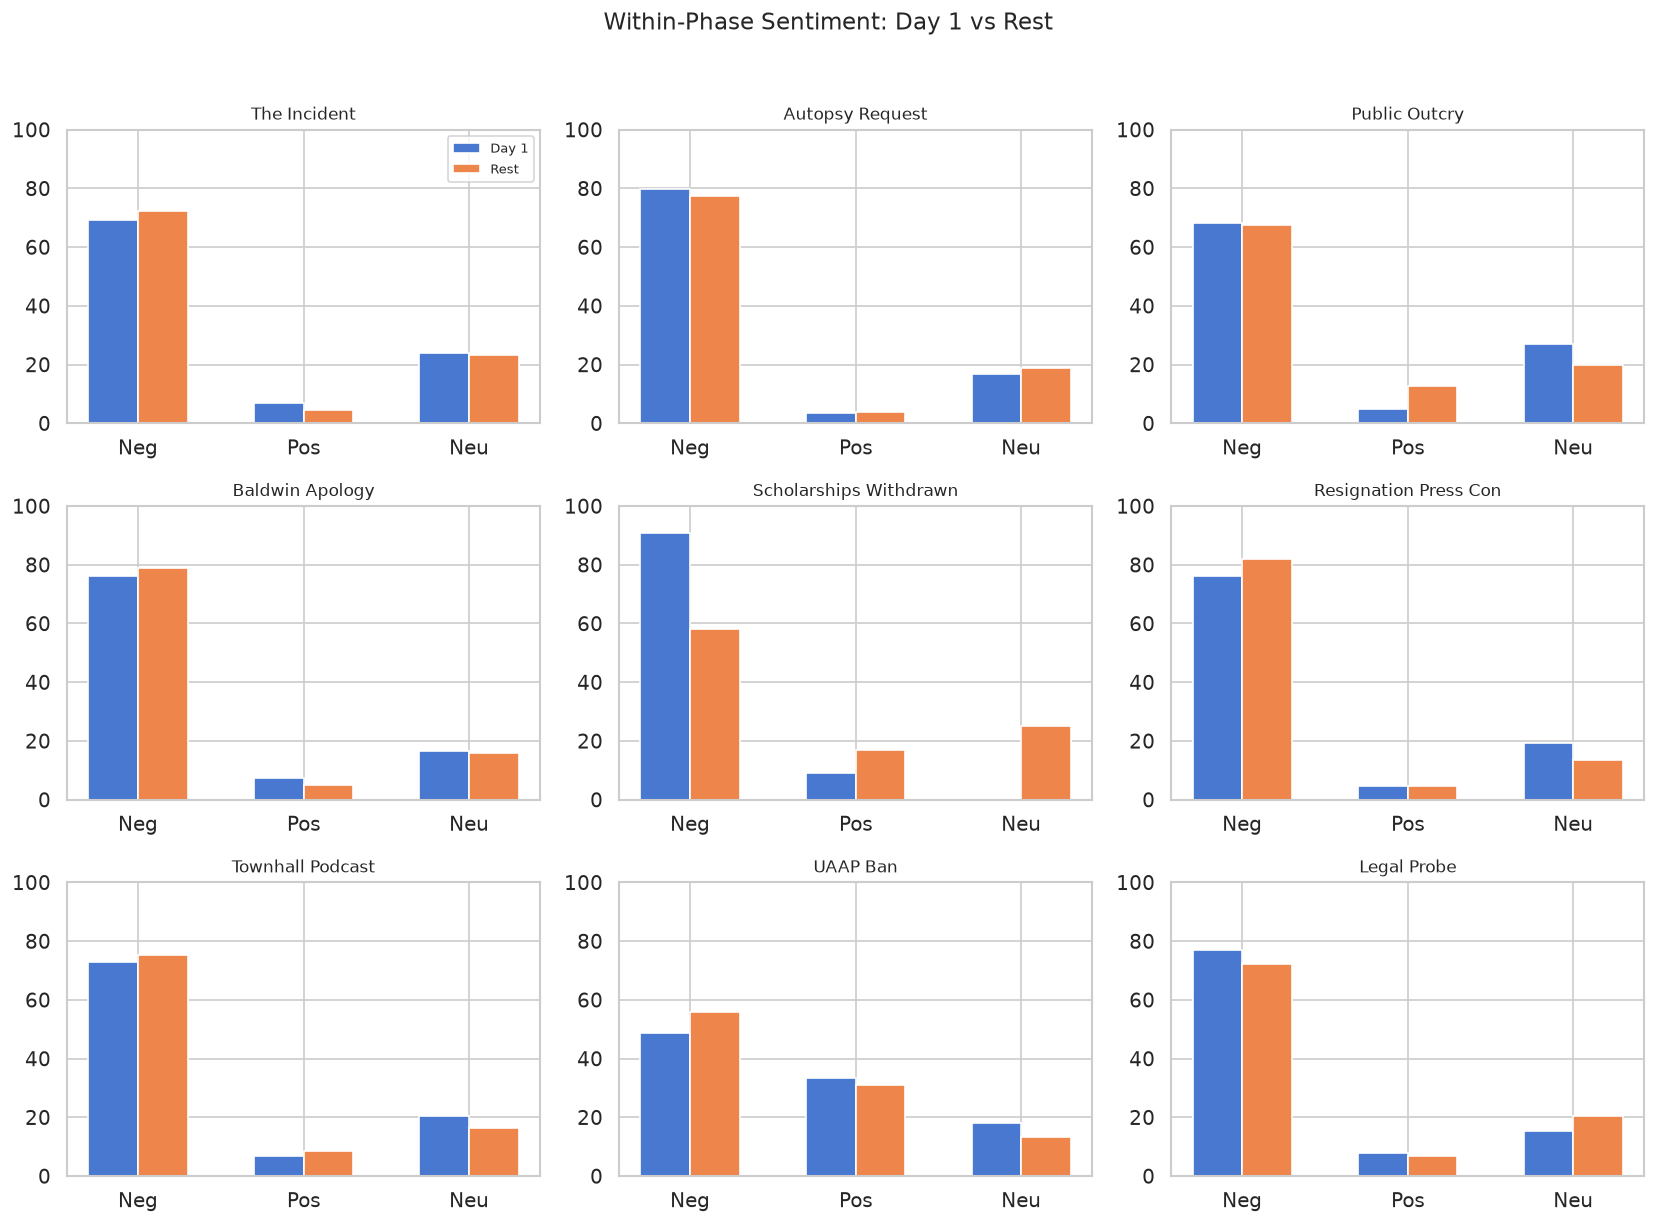

In [31]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for idx, phase in enumerate(PHASE_ORDER):
    ax = axes[idx]
    pair = day1_df[day1_df["phase"] == phase]
    if len(pair) == 0:
        ax.set_visible(False)
        continue

    x = np.arange(3)
    width = 0.3

    for i, w in enumerate(["Day 1", "Rest"]):
        row = pair[pair["window"] == w]
        if len(row) == 0:
            continue
        vals = [row["pct_neg"].values[0], row["pct_pos"].values[0], row["pct_neu"].values[0]]
        ax.bar(x + i * width, vals, width, label=w if idx == 0 else None)

    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(["Neg", "Pos", "Neu"])
    ax.set_title(PHASE_DISPLAY[phase], fontsize=10)
    ax.set_ylim(0, 100)
    if idx == 0:
        ax.legend(fontsize=8)

fig.suptitle("Within-Phase Sentiment: Day 1 vs Rest", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary_day1_vs_rest_faceted.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
print("Within-phase comparison: Day 1 vs Rest")
header = f"{'Phase':30s} {'Day1 N':>6s} {'Rest N':>6s} {'Chi2':>8s} {'p':>8s} {'Cramer V':>8s} {'Sig?':>6s}"
print(header)
print("-" * 75)

results = []
for phase in day1_df["phase"].unique():
    pair = day1_df[day1_df["phase"] == phase]
    if len(pair) < 2:
        continue

    day1_row = pair[pair["window"] == "Day 1"].iloc[0]
    rest_row = pair[pair["window"] == "Rest"].iloc[0]

    contingency = np.array([
        [day1_row["pct_neg"] * day1_row["total"] / 100,
         day1_row["pct_pos"] * day1_row["total"] / 100,
         day1_row["pct_neu"] * day1_row["total"] / 100],
        [rest_row["pct_neg"] * rest_row["total"] / 100,
         rest_row["pct_pos"] * rest_row["total"] / 100,
         rest_row["pct_neu"] * rest_row["total"] / 100],
    ])

    chi2, p, _, _ = chi2_contingency(contingency)
    n = contingency.sum()
    cramer_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

    sig = "YES" if p < 0.05 else "no"
    results.append({
        "phase": phase,
        "label": PHASE_DISPLAY[phase],
        "day1_n": int(day1_row["total"]),
        "rest_n": int(rest_row["total"]),
        "delta_neg": rest_row["pct_neg"] - day1_row["pct_neg"],
        "delta_polarity": rest_row["polarity"] - day1_row["polarity"],
        "chi2": chi2,
        "p": p,
        "cramer_v": cramer_v,
        "significant": sig,
    })

    print(
        f"{PHASE_DISPLAY[phase]:30s} {int(day1_row['total']):6d} "
        f"{int(rest_row['total']):6d} {chi2:8.2f} {p:8.4f} {cramer_v:8.4f} {sig:>6s}"
    )

results_df = pd.DataFrame(results)
print()
print("Delta interpretation:")
print("  delta_neg = Rest %neg - Day1 %neg (positive = outrage decays)")
print("  delta_polarity = Rest polarity - Day1 polarity (positive = sentiment improves)")

Within-phase comparison: Day 1 vs Rest
Phase                          Day1 N Rest N     Chi2        p Cramer V   Sig?
---------------------------------------------------------------------------
The Incident                      172    685     1.82   0.4015   0.0461     no
Autopsy Request                   467   1932     1.30   0.5221   0.0233     no
Public Outcry                      63    191     3.82   0.1483   0.1226     no
Baldwin Apology                   499    253     1.53   0.4650   0.0451     no
Scholarships Withdrawn             11    531     5.14   0.0765   0.0974     no
Resignation Press Con             155    154     1.85   0.3971   0.0773     no
Townhall Podcast                 3538   1597    13.35   0.0013   0.0510    YES
UAAP Ban                           39     61     0.63   0.7308   0.0792     no
Legal Probe                        13    246     0.20   0.9069   0.0275     no

Delta interpretation:
  delta_neg = Rest %neg - Day1 %neg (positive = outrage decays)
  delta_

In [33]:
sig_count = (results_df["p"] < 0.05).sum()
print(f"Phases with significant Day 1 / Rest difference: {sig_count}/{len(results_df)}")
print()
print("Key finding: Only the Townhall Podcast phase shows a statistically significant")
print("shift between Day 1 and Rest (p=0.0013), and the effect size is small (Cramer's V=0.051).")
print("For all other phases, within-phase sentiment is stable — initial outrage neither decays")
print("nor intensifies significantly.")
print()
print("Largest magnitude shifts (though not statistically significant):")
results_df["abs_delta_neg"] = results_df["delta_neg"].abs()
shifted = results_df.sort_values("abs_delta_neg", ascending=False)
for _, row in shifted.iterrows():
    arrow = chr(8593) if row["delta_neg"] > 0 else chr(8595)
    print(
        f"  {row['label']:30s} {arrow} {abs(row['delta_neg']):.1f}pp neg "
        f"(p={row['p']:.4f})"
    )

Phases with significant Day 1 / Rest difference: 1/9

Key finding: Only the Townhall Podcast phase shows a statistically significant
shift between Day 1 and Rest (p=0.0013), and the effect size is small (Cramer's V=0.051).
For all other phases, within-phase sentiment is stable — initial outrage neither decays
nor intensifies significantly.

Largest magnitude shifts (though not statistically significant):
  Scholarships Withdrawn         ↓ 32.9pp neg (p=0.0765)
  UAAP Ban                       ↑ 7.0pp neg (p=0.7308)
  Resignation Press Con          ↑ 5.7pp neg (p=0.3971)
  Legal Probe                    ↓ 4.6pp neg (p=0.9069)
  The Incident                   ↑ 2.9pp neg (p=0.4015)
  Baldwin Apology                ↑ 2.9pp neg (p=0.4650)
  Autopsy Request                ↓ 2.4pp neg (p=0.5221)
  Townhall Podcast               ↑ 2.4pp neg (p=0.0013)
  Public Outcry                  ↓ 0.7pp neg (p=0.1483)


---
## 4. Topics Per Phase

For each phase, we identify the top-3 most prevalent topics and compute their sentiment polarity. This reveals what people were talking about during each crisis event and whether certain themes carry more outrage than others.

In [34]:
topic_phases = df.dropna(subset=["topic_label"]).copy()

top_topics = []
for phase in PHASE_ORDER:
    phase_topics = topic_phases[topic_phases["phase"] == phase]
    total = len(phase_topics)
    if total == 0:
        continue

    topic_counts = phase_topics["topic_label"].value_counts()
    for rank, (topic, count) in enumerate(topic_counts.head(3).items(), 1):
        pct = count / total * 100
        topic_sub = phase_topics[phase_topics["topic_label"] == topic]
        neg = (topic_sub["sentiment_label"] == "NEGATIVE").sum()
        pos = (topic_sub["sentiment_label"] == "POSITIVE").sum()
        pol = (pos - neg) / count * 100 if count else 0
        top_topics.append({
            "phase": PHASE_DISPLAY[phase], "rank": rank, "topic": topic,
            "n": count, "pct": pct, "polarity": pol,
        })

top3_df = pd.DataFrame(top_topics)
display(top3_df[["phase", "rank", "topic", "n", "pct", "polarity"]].round(1))

,phase,rank,topic,n,pct,polarity
0,The Incident,1,Drowning Incident,294,47.0,-64.3
1,The Incident,2,Ateneo Training Tragedy,129,20.6,-69.8
2,The Incident,3,Beach Safety Oversight,104,16.6,-63.5
3,Autopsy Request,1,CPR Cessation Controversy,716,44.9,-77.5
4,Autopsy Request,2,Dangerous Water Training,422,26.5,-68.5
5,Autopsy Request,3,Accountability and Justice,191,12.0,-75.4
6,Public Outcry,1,ADMU Hazing Controversy,49,27.7,-20.4
7,Public Outcry,2,Ateneo Coaching Accountability,40,22.6,-67.5
8,Public Outcry,3,Hazing Tragedy Reactions,38,21.5,-71.1
9,Baldwin Apology,1,Accountability and Classism,183,33.1,-57.4


### Topic Sentiment Polarity by Phase

Heatmap showing the sentiment polarity index for each topic across crisis phases. 
Topics are filtered to those with data in at least 2 phases. 
The polarity index ranges from -100 (all negative) to +100 (all positive), with 0 indicating neutral sentiment.

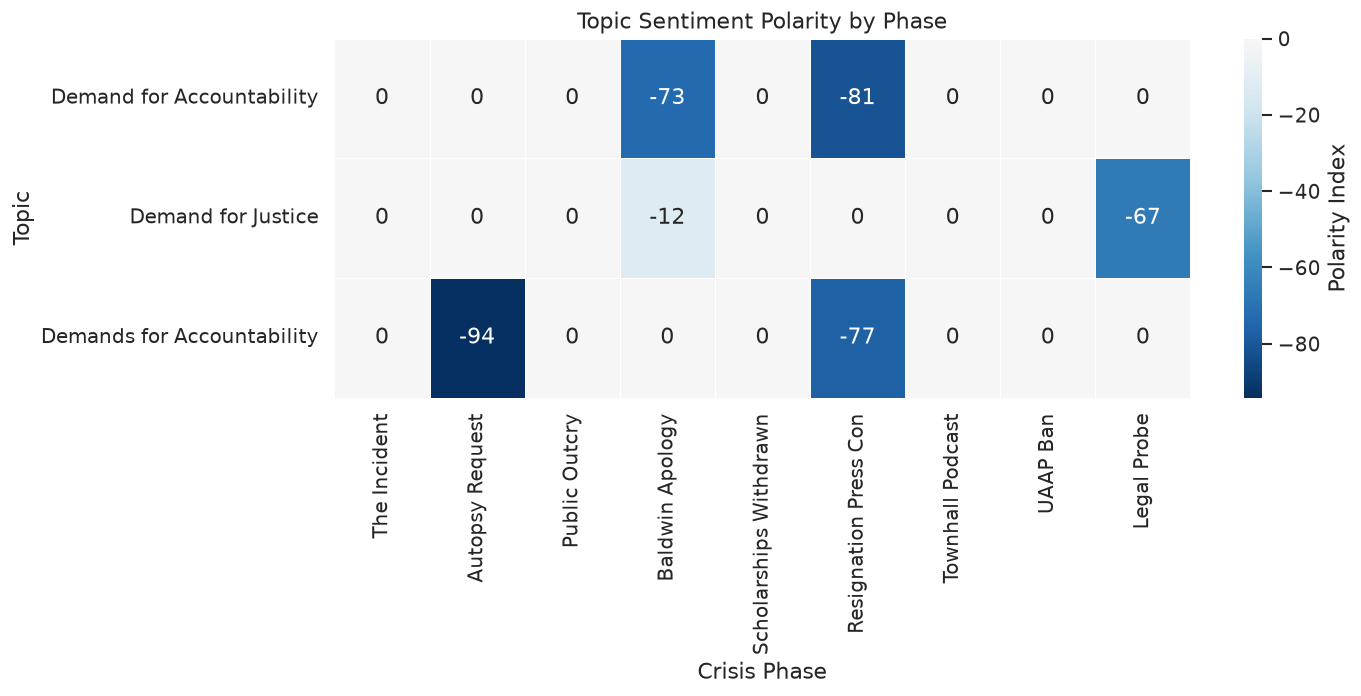

In [35]:
topic_polarity = (
    topic_phases
    .groupby(["topic_label", "phase"])
    .apply(
        lambda x: ((x["sentiment_label"] == "POSITIVE").sum()
                   - (x["sentiment_label"] == "NEGATIVE").sum())
                  / len(x) * 100
    )
    .reset_index(name="polarity")
)

topic_pivot = topic_polarity.pivot(
    index="topic_label", columns="phase", values="polarity"
)
available = [c for c in PHASE_ORDER if c in topic_pivot.columns]
topic_pivot = topic_pivot[available]
topic_pivot.columns = [PHASE_DISPLAY[c] for c in topic_pivot.columns]

# Filter to topics that appear in at least 2 phases
# (requires validated/harmonized labels -- pre-validation every label is
#  phase-unique, so the pivot can be empty; skip instead of crashing)
topic_pivot = topic_pivot.dropna(thresh=2)

if topic_pivot.empty:
    print("SKIP: no topics span 2+ phases (run topic validation first).")
else:
    topic_pivot = topic_pivot.fillna(0)

    fig, ax = plt.subplots(figsize=(12, max(6, len(topic_pivot) * 0.4)))
    sns.heatmap(topic_pivot, cmap="RdBu_r", center=0, annot=True, fmt=".0f",
                linewidths=0.5, ax=ax, cbar_kws={"label": "Polarity Index"})
    ax.set_title("Topic Sentiment Polarity by Phase")
    ax.set_xlabel("Crisis Phase")
    ax.set_ylabel("Topic")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "summary_topic_phase_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()

### Topic Sentiment Polarity by Phase (All Topics)

Heatmap showing sentiment polarity for all identified topics across every crisis phase. 
Unlike the filtered view above, this includes all topics regardless of how few phases they appear in, 
providing a complete picture of topic-level sentiment distribution.

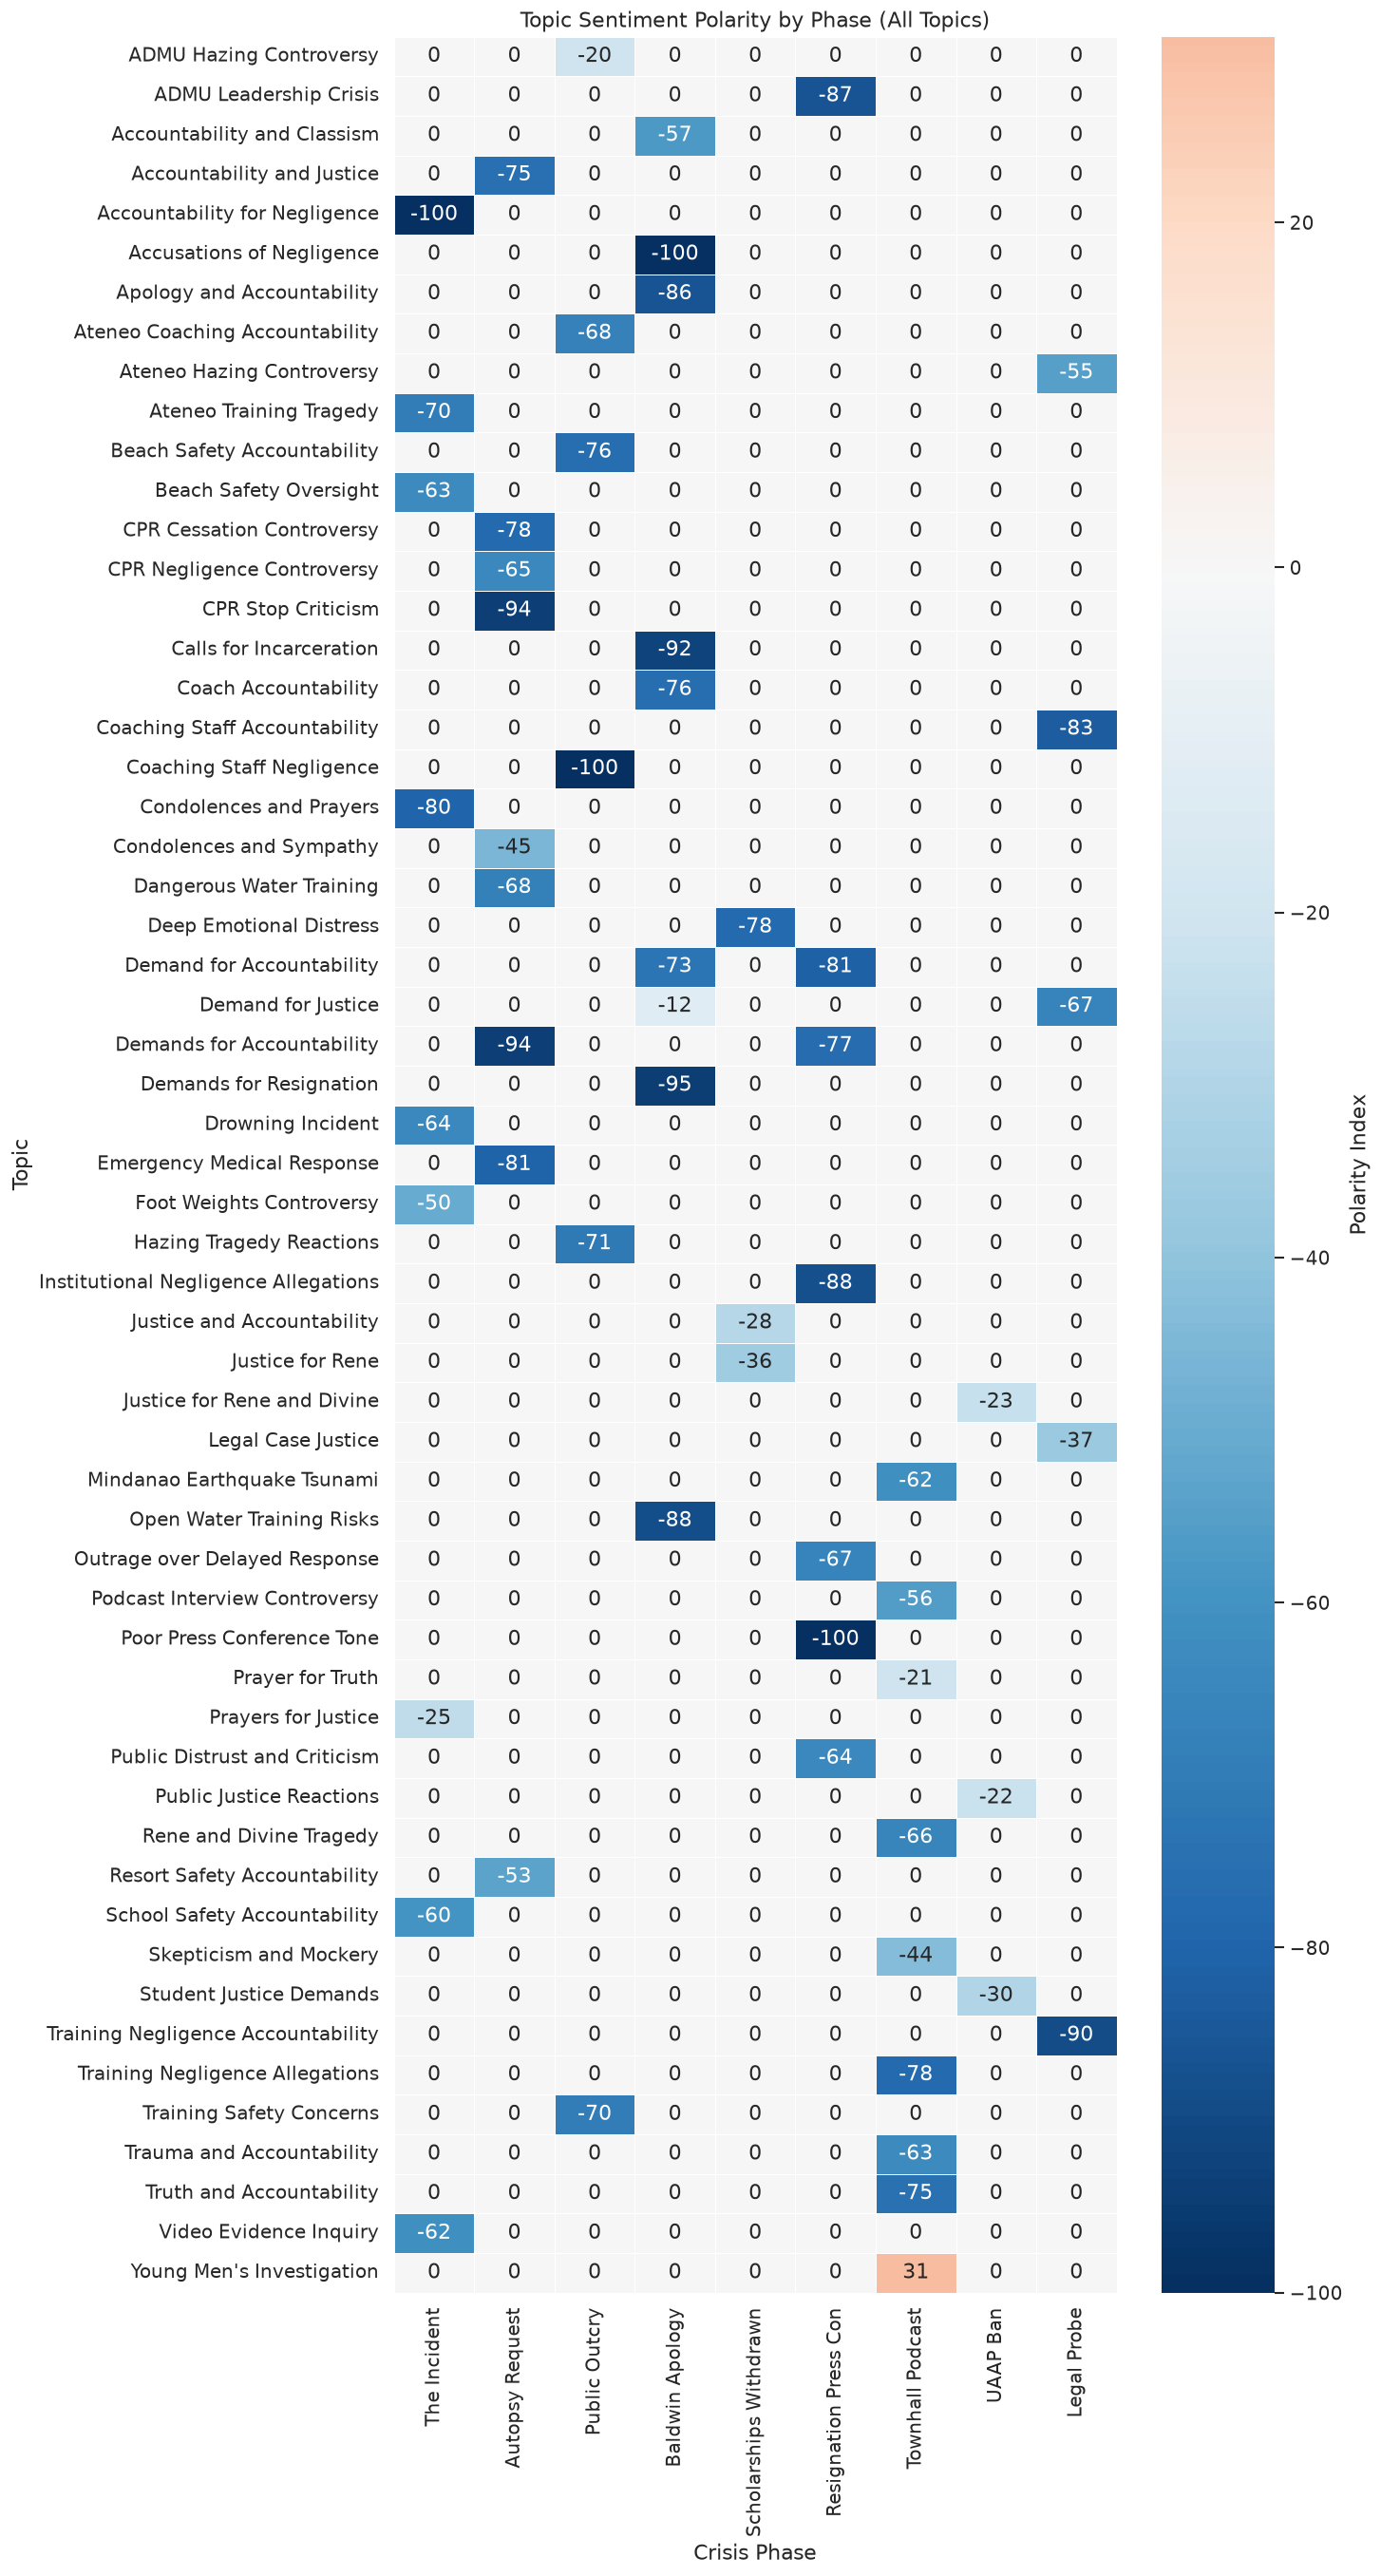

In [36]:
topic_polarity_all = (
    topic_phases
    .groupby(["topic_label", "phase"])
    .apply(
        lambda x: ((x["sentiment_label"] == "POSITIVE").sum()
                   - (x["sentiment_label"] == "NEGATIVE").sum())
                  / len(x) * 100
    )
    .reset_index(name="polarity")
)

topic_pivot_all = topic_polarity_all.pivot(
    index="topic_label", columns="phase", values="polarity"
)
available_all = [c for c in PHASE_ORDER if c in topic_pivot_all.columns]
topic_pivot_all = topic_pivot_all[available_all]
topic_pivot_all.columns = [PHASE_DISPLAY[c] for c in topic_pivot_all.columns]

topic_pivot_all = topic_pivot_all.fillna(0)

fig, ax = plt.subplots(figsize=(12, max(6, len(topic_pivot_all) * 0.4)))
sns.heatmap(topic_pivot_all, cmap="RdBu_r", center=0, annot=True, fmt=".0f",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Polarity Index"})
ax.set_title("Topic Sentiment Polarity by Phase (All Topics)")
ax.set_xlabel("Crisis Phase")
ax.set_ylabel("Topic")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary_topic_phase_heatmap_all.png", dpi=150, bbox_inches="tight")
plt.show()

### Topic Sentiment Polarity by Phase (Top 10 Topics)

Heatmap showing sentiment polarity for the 10 most frequently discussed topics across all crisis phases. 
Topics are ranked by total comment volume. This view highlights the dominant conversations 
and how their sentiment shifted throughout the crisis timeline.

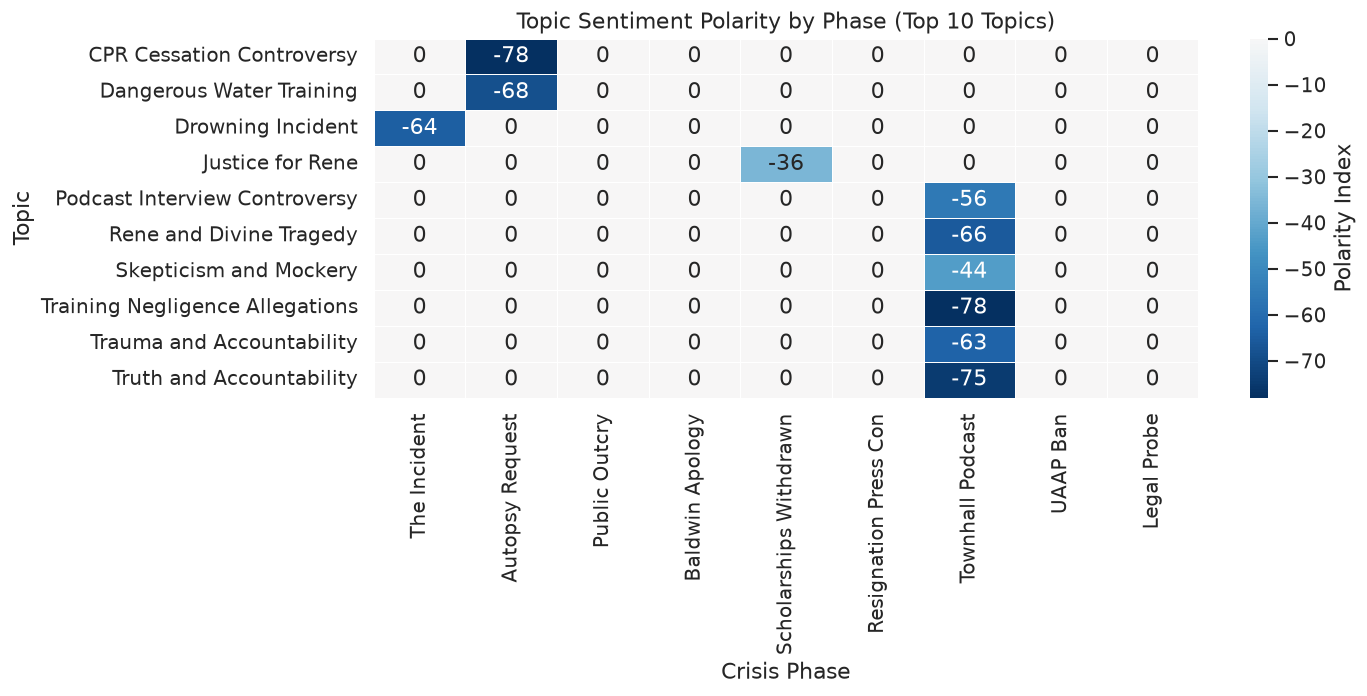

In [37]:
topic_polarity = (
    topic_phases
    .groupby(["topic_label", "phase"])
    .apply(
        lambda x: ((x["sentiment_label"] == "POSITIVE").sum()
                   - (x["sentiment_label"] == "NEGATIVE").sum())
                  / len(x) * 100
    )
    .reset_index(name="polarity")
)

topic_pivot = topic_polarity.pivot(
    index="topic_label", columns="phase", values="polarity"
)
topic_pivot = topic_pivot.reindex(columns=PHASE_ORDER)
topic_pivot.columns = [PHASE_DISPLAY[c] for c in topic_pivot.columns]

topic_counts = topic_phases.groupby("topic_label").size().sort_values(ascending=False)
top10_topics = topic_counts.head(10).index
topic_pivot = topic_pivot.loc[topic_pivot.index.isin(top10_topics)]

topic_pivot = topic_pivot.fillna(0)

fig, ax = plt.subplots(figsize=(12, max(6, len(topic_pivot) * 0.4)))
sns.heatmap(topic_pivot, cmap="RdBu_r", center=0, annot=True, fmt=".0f",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Polarity Index"})
ax.set_title("Topic Sentiment Polarity by Phase (Top 10 Topics)")
ax.set_xlabel("Crisis Phase")
ax.set_ylabel("Topic")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary_topic_phase_heatmap_top10.png", dpi=150, bbox_inches="tight")
plt.show()

In [38]:
topic_overall = (
    topic_phases.groupby("topic_label")
    .agg(
        total_comments=("sentiment_label", "count"),
        n_neg=("sentiment_label", lambda x: (x == "NEGATIVE").sum()),
        n_pos=("sentiment_label", lambda x: (x == "POSITIVE").sum()),
    )
    .reset_index()
)
topic_overall = topic_overall[topic_overall["total_comments"] >= 10].copy()
topic_overall["pct_neg"] = topic_overall["n_neg"] / topic_overall["total_comments"] * 100
topic_overall["pct_pos"] = topic_overall["n_pos"] / topic_overall["total_comments"] * 100
topic_overall["polarity"] = topic_overall["pct_pos"] - topic_overall["pct_neg"]

most_angry = topic_overall.sort_values("pct_neg", ascending=False).head(5)
most_positive = topic_overall.sort_values("pct_pos", ascending=False).head(5)

print("Most negative topics (top 5):")
for _, row in most_angry.iterrows():
    print(f"  {row['topic_label']:40s} {row['pct_neg']:5.1f}% neg  ({int(row['total_comments']):4d} comments)")
print()
print("Most positive topics (top 5):")
for _, row in most_positive.iterrows():
    print(f"  {row['topic_label']:40s} {row['pct_pos']:5.1f}% pos  ({int(row['total_comments']):4d} comments)")

Most negative topics (top 5):
  Accountability for Negligence            100.0% neg  (  13 comments)
  Accusations of Negligence                100.0% neg  (  28 comments)
  Coaching Staff Negligence                100.0% neg  (  19 comments)
  Poor Press Conference Tone               100.0% neg  (  31 comments)
  Demands for Resignation                   94.7% neg  (  19 comments)

Most positive topics (top 5):
  Young Men's Investigation                 53.8% pos  (  13 comments)
  Justice for Rene and Divine               35.9% pos  (  39 comments)
  Student Justice Demands                   30.0% pos  (  20 comments)
  ADMU Hazing Controversy                   22.4% pos  (  49 comments)
  Justice and Accountability                21.1% pos  (  95 comments)


---
## 5. Topic Trajectory Across Phases

How do topics evolve as the crisis progresses? We track which topics appear in multiple phases (persistent) vs. those unique to a single phase. We also identify the dominant topic at each phase to see how the conversation shifts at each new revelation.

In [39]:
topic_phase_count = (
    topic_phases.groupby("topic_label")["phase"]
    .nunique()
    .reset_index(name="n_phases")
    .sort_values("n_phases", ascending=False)
)

persistent = topic_phase_count[topic_phase_count["n_phases"] > 1]
phase_specific = topic_phase_count[topic_phase_count["n_phases"] == 1]

print(f"Topics appearing in multiple phases (persistent): {len(persistent)}")
for _, row in persistent.iterrows():
    print(f"  {row['topic_label']:40s} appears in {int(row['n_phases'])} phases")

print()
print(f"Topics confined to a single phase (phase-specific): {len(phase_specific)}")
for _, row in phase_specific.iterrows():
    print(f"  {row['topic_label']:40s}")

print()
print("---")
print("Dominant topic per phase:")
for phase in PHASE_ORDER:
    phase_data = topic_phases[topic_phases["phase"] == phase]
    if len(phase_data) == 0:
        continue
    dominant = phase_data["topic_label"].value_counts().idxmax()
    count = phase_data["topic_label"].value_counts().max()
    pct = count / len(phase_data) * 100
    print(f"  {PHASE_DISPLAY[phase]:30s} \"{dominant}\"  ({pct:.0f}% of labeled comments)")

Topics appearing in multiple phases (persistent): 3
  Demand for Justice                       appears in 2 phases
  Demand for Accountability                appears in 2 phases
  Demands for Accountability               appears in 2 phases

Topics confined to a single phase (phase-specific): 54
  ADMU Leadership Crisis                  
  Accountability and Classism             
  Accusations of Negligence               
  Apology and Accountability              
  Accountability and Justice              
  Accountability for Negligence           
  Ateneo Hazing Controversy               
  Ateneo Coaching Accountability          
  Ateneo Training Tragedy                 
  Beach Safety Accountability             
  CPR Negligence Controversy              
  CPR Stop Criticism                      
  Beach Safety Oversight                  
  CPR Cessation Controversy               
  Coach Accountability                    
  Calls for Incarceration                 
  Coaching Staf

### Topic River: Thematic Composition Across Phases

A streamgraph showing how the thematic composition of public discourse shifts across crisis phases. Each colored band represents a topic; band thickness corresponds to the proportion of labeled comments in that topic during each phase. Only the top 20 most prevalent topics are shown individually; remaining topics are grouped as "Other." The red line overlays the overall polarity index (%positive − %negative) to connect thematic composition with emotional valence.

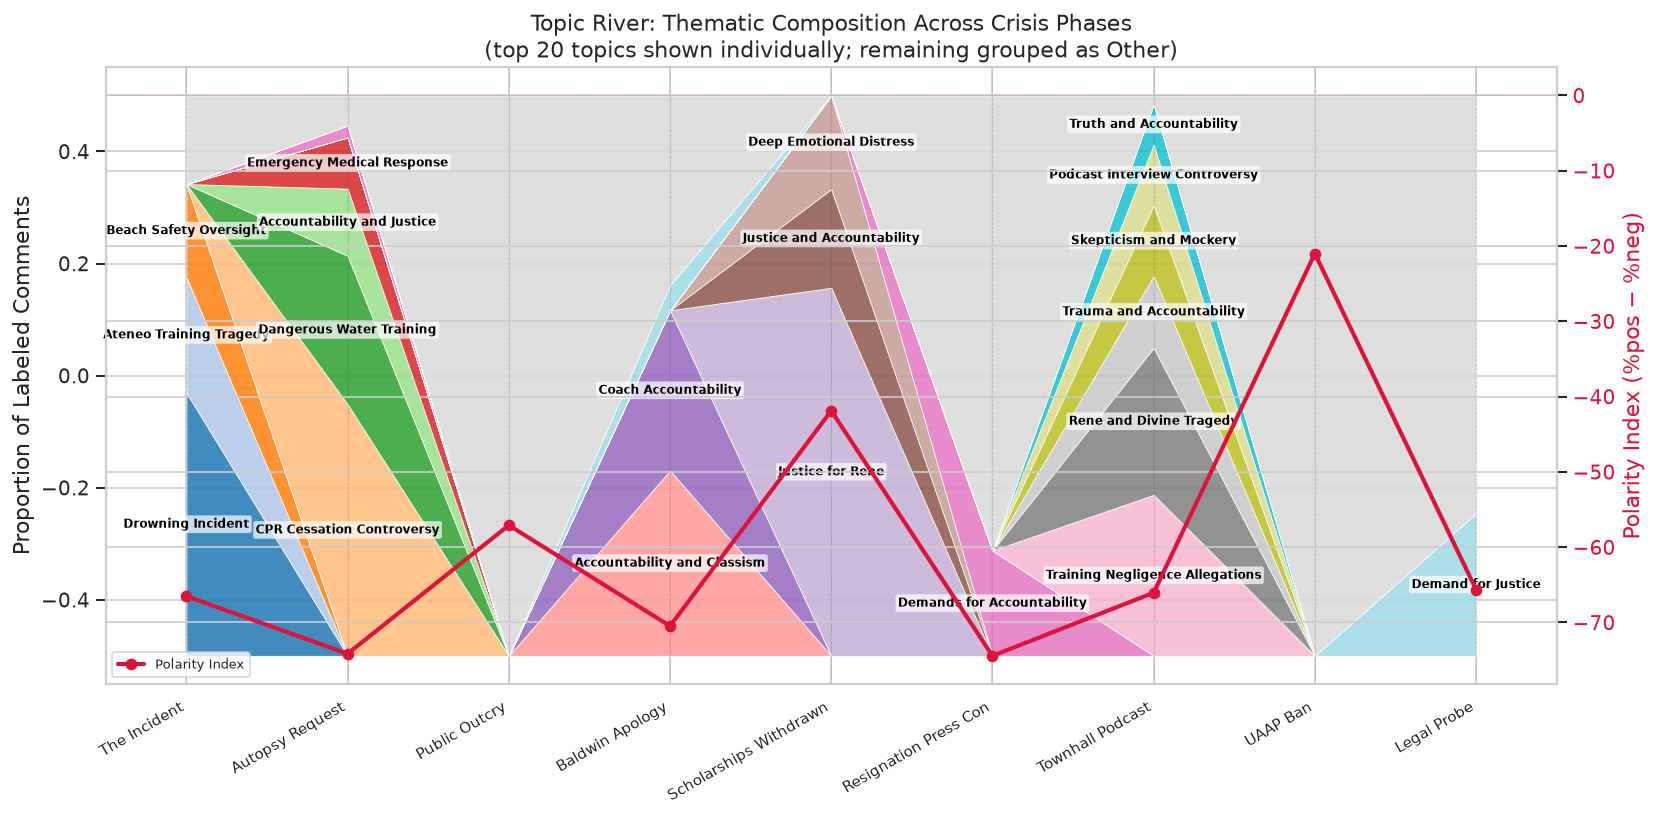

In [ ]:
# Build per-phase topic proportion matrix for the streamgraph
topic_phases_clean = df.dropna(subset=["topic_label"]).copy()

# Count comments per topic per phase, then normalize within each phase
counts = (
    topic_phases_clean
    .groupby(["phase", "topic_label"])
    .size()
    .reset_index(name="count")
)

# Compute total labeled comments per phase for normalization
phase_totals = counts.groupby("phase")["count"].transform("sum")
counts["proportion"] = counts["count"] / phase_totals

# Identify top 20 topics by total comment count across all phases
topic_totals = counts.groupby("topic_label")["count"].sum().sort_values(ascending=False)
top20 = topic_totals.head(20).index.tolist()

# Pivot to wide format: rows=topics, cols=phases, values=proportion
pivot = counts.pivot_table(
    index="topic_label", columns="phase", values="proportion", aggfunc="sum", fill_value=0
)

# Ensure all phases are present as columns in order
for p in PHASE_ORDER:
    if p not in pivot.columns:
        pivot[p] = 0.0
pivot = pivot[PHASE_ORDER]

# Separate top 20 and "Other"
top20_pivot = pivot.loc[pivot.index.isin(top20)]
other_per_phase = 1 - top20_pivot.sum(axis=0)
other_per_phase = other_per_phase.clip(lower=0)  # guard against rounding

# Sort topics by phase of peak prevalence, then by peak value
# This groups topics that appear in the same phase together, reducing visual jumps
def phase_of_peak(row):
    return PHASE_ORDER.index(row.idxmax())

top20_pivot["_peak_phase"] = top20_pivot.apply(phase_of_peak, axis=1)
top20_pivot["_peak_val"] = top20_pivot[PHASE_ORDER].max(axis=1)
top20_pivot = top20_pivot.sort_values(["_peak_phase", "_peak_val"], ascending=[True, False])
top20_pivot = top20_pivot.drop(columns=["_peak_phase", "_peak_val"])

# Build the stacked data arrays
topic_names = top20_pivot.index.tolist()
topic_arrays = [top20_pivot.loc[t].values for t in topic_names]
other_array = other_per_phase.values

# Phase labels for x-axis
phase_labels = [PHASE_DISPLAY[p] for p in PHASE_ORDER]
x = np.arange(len(PHASE_ORDER))

# Color palette
cmap = plt.colormaps["tab20"].resampled(20)
colors = [cmap(i) for i in range(20)]
other_color = (0.85, 0.85, 0.85, 0.8)  # light gray for Other

# Plot the streamgraph
fig, ax1 = plt.subplots(figsize=(14, 7))

stacks = ax1.stackplot(
    x,
    *topic_arrays,
    other_array,
    labels=[*topic_names, "Other"],
    colors=[*colors, other_color],
    baseline="sym",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5,
)

# Annotate major bands (> 5% at their peak phase)
cumul = np.zeros(len(PHASE_ORDER))  # track vertical position for annotation
# Recompute with symmetric baseline to find center positions
all_arrays = topic_arrays + [other_array]
all_names = topic_names + ["Other"]
all_colors = colors + [other_color]
total_per_phase = np.sum([a for a in all_arrays], axis=0)
half_total = total_per_phase / 2

running = -half_total  # start from bottom of symmetric baseline
for arr, name, clr in zip(all_arrays, all_names, all_colors):
    peak_pct = arr.max() * 100
    if peak_pct > 5 and name != "Other":
        peak_idx = arr.argmax()
        # Vertical center of this band at its peak
        band_center = running[peak_idx] + arr[peak_idx] / 2
        ax1.annotate(
            name,
            xy=(peak_idx, band_center),
            fontsize=7,
            fontweight="bold",
            ha="center", va="center",
            color="black",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none"),
        )
    running = running + arr

# Phase boundary markers
for i in range(len(PHASE_ORDER)):
    ax1.axvline(x=i, color="gray", linewidth=0.5, linestyle="--", alpha=0.4)

# X-axis configuration
ax1.set_xticks(x)
ax1.set_xticklabels(phase_labels, rotation=30, ha="right", fontsize=9)
ax1.set_xlim(-0.5, len(PHASE_ORDER) - 0.5)
ax1.set_ylabel("Proportion of Labeled Comments")
ax1.set_title(
    "Topic River: Thematic Composition Across Crisis Phases"
)

# Overlay polarity index on twin axis
ax2 = ax1.twinx()
# Compute polarity per phase from the full merged dataframe
pol_per_phase = []
for phase in PHASE_ORDER:
    phase_df = df[df["phase"] == phase]
    n = len(phase_df)
    neg = (phase_df["sentiment_label"] == "NEGATIVE").sum()
    pos = (phase_df["sentiment_label"] == "POSITIVE").sum()
    pol_per_phase.append((pos - neg) / n * 100 if n else 0)

ax2.plot(x, pol_per_phase, color="crimson", linewidth=2.5, marker="o",
         markersize=6, zorder=5, label="Polarity Index")
ax2.set_ylabel("Polarity Index (%pos \u2212 %neg)", color="crimson")
ax2.tick_params(axis="y", labelcolor="crimson")
ax2.axhline(y=0, color="crimson", linewidth=0.5, linestyle=":", alpha=0.5)

# Legend for polarity line
ax2.legend(loc="lower left", fontsize=8, framealpha=0.8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary_topic_river.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The streamgraph confirms the finding from Section 5 that topics are largely phase-specific — most bands appear, dominate, and disappear within a single crisis phase. The thematic composition resets almost entirely at each new revelation:

- **Early phases** (The Incident, Autopsy Request) are dominated by drowning and CPR-related topics
- **Mid-crisis** (Baldwin Apology, Scholarships Withdrawn) shifts to accountability, classism, and emotional distress
- **Late phases** (Townhall Podcast, UAAP Ban, Legal Probe) center on negligence allegations, justice demands, and institutional accountability

The overlay of polarity index shows that thematic shifts do not consistently drive sentiment improvement or worsening — the conversation remains deeply negative regardless of which topics dominate.

---
## 6. Additional Analyses

Beyond the phase-level summaries above, we examine sentiment across phase boundaries to quantify how much each new crisis revelation moved public sentiment.

### 6a. Phase Boundary Sentiment Shifts

For each adjacent phase transition, we compare sentiment in the 3 days before the boundary vs. the 3 days after. This quantifies how much each new revelation actually moved public sentiment. A Mann-Whitney U test determines whether the shift is statistically significant.

In [41]:
from scipy.stats import mannwhitneyu

boundaries = []
for i in range(len(PHASE_ORDER) - 1):
    phase_a = PHASE_ORDER[i]
    phase_b = PHASE_ORDER[i + 1]

    boundary_date = df[df["phase"] == phase_b]["create_time"].min()
    label_a = PHASE_DISPLAY[phase_a]
    label_b = PHASE_DISPLAY[phase_b]

    window_start = boundary_date - pd.Timedelta(days=3)
    window_end = boundary_date + pd.Timedelta(days=3)

    before = df[(df["create_time"] >= window_start) & (df["create_time"] < boundary_date)]
    after = df[(df["create_time"] >= boundary_date) & (df["create_time"] <= window_end)]

    if len(before) == 0 or len(after) == 0:
        continue

    def polarity(subset):
        neg = (subset["sentiment_label"] == "NEGATIVE").sum()
        pos = (subset["sentiment_label"] == "POSITIVE").sum()
        total = len(subset)
        return (pos - neg) / total * 100 if total else 0

    pol_before = polarity(before)
    pol_after = polarity(after)
    pct_neg_before = (before["sentiment_label"] == "NEGATIVE").sum() / len(before) * 100
    pct_neg_after = (after["sentiment_label"] == "NEGATIVE").sum() / len(after) * 100

    scores_before = before["sentiment_score"].values
    scores_after = after["sentiment_score"].values
    u_stat, p_value = mannwhitneyu(scores_before, scores_after, alternative="two-sided")

    boundaries.append({
        "transition": f"{label_a}  >>>  {label_b}",
        "boundary_date": boundary_date,
        "n_before": len(before),
        "n_after": len(after),
        "pol_before": pol_before,
        "pol_after": pol_after,
        "delta_pol": pol_after - pol_before,
        "pct_neg_before": pct_neg_before,
        "pct_neg_after": pct_neg_after,
        "delta_neg": pct_neg_after - pct_neg_before,
        "u_stat": u_stat,
        "p_value": p_value,
    })

boundary_df = pd.DataFrame(boundaries)

print("Phase boundary sentiment shifts (3d before vs 3d after):")
print()
display(
    boundary_df[["transition", "n_before", "n_after", "pol_before", "pol_after",
                 "delta_pol", "delta_neg", "p_value"]].round(2)
)

Phase boundary sentiment shifts (3d before vs 3d after):



,transition,n_before,n_after,pol_before,pol_after,delta_pol,delta_neg,p_value
0,Autopsy Request >>> Public Outcry,1282,1817,-69.19,-63.79,5.40,-2.44,0.94
1,Public Outcry >>> Baldwin Apology,1549,1969,-68.30,-64.70,3.60,-1.19,0.88
2,Baldwin Apology >>> Scholarships Withdrawn,1549,1969,-68.30,-64.70,3.60,-1.19,0.88
3,Scholarships Withdrawn >>> Resignation Press...,1550,6172,-63.74,-66.61,-2.87,2.43,NaN
4,Resignation Press Con >>> Townhall Podcast,1134,6097,-63.76,-66.49,-2.74,2.84,NaN
5,Townhall Podcast >>> UAAP Ban,5753,1183,-66.49,-67.71,-1.22,2.26,NaN
6,UAAP Ban >>> Legal Probe,1550,6172,-63.74,-66.61,-2.87,2.43,NaN


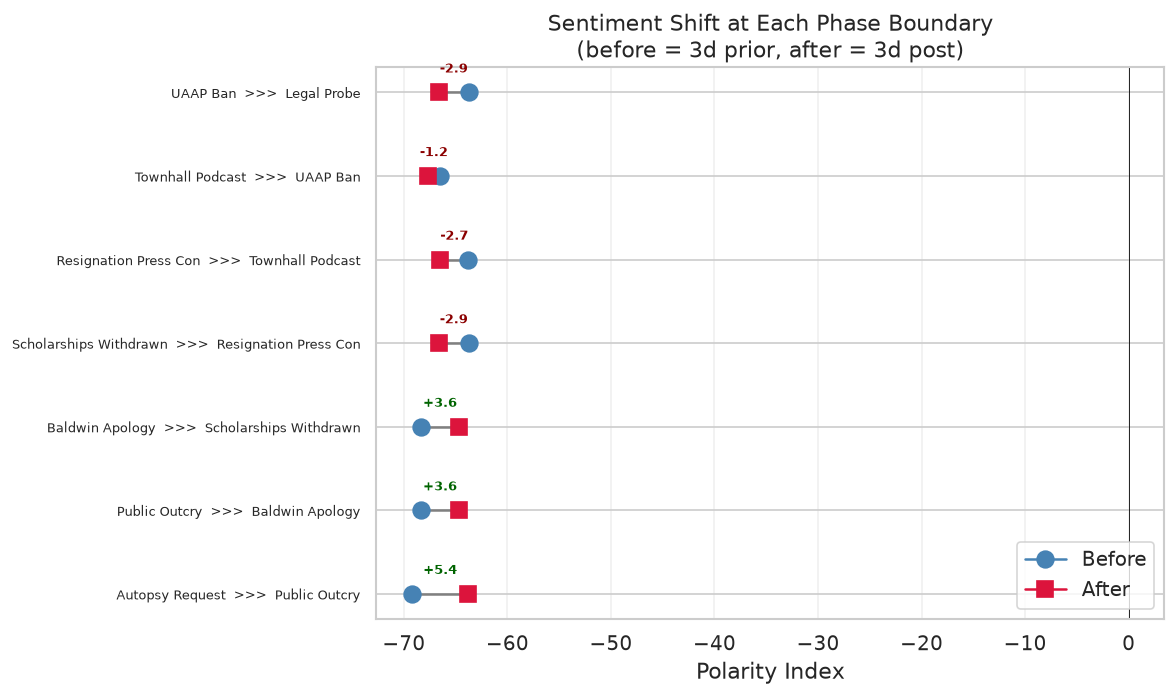

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(boundary_df))

for i, (_, row) in enumerate(boundary_df.iterrows()):
    ax.plot([row["pol_before"], row["pol_after"]], [i, i],
            color="gray", linewidth=1.5, zorder=1)
    ax.plot(row["pol_before"], i, marker="o", color="steelblue",
            markersize=10, label="Before" if i == 0 else "", zorder=2)
    ax.plot(row["pol_after"], i, marker="s", color="crimson",
            markersize=10, label="After" if i == 0 else "", zorder=2)

    delta = row["delta_pol"]
    mid = (row["pol_before"] + row["pol_after"]) / 2
    ax.annotate(f"{delta:+.1f}",
                xy=(mid, i), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=8, fontweight="bold",
                color="darkgreen" if delta > 0 else "darkred")

ax.set_yticks(y_pos)
ax.set_yticklabels(boundary_df["transition"], fontsize=8)
ax.axvline(x=0, color="black", linewidth=0.5)
ax.set_xlabel("Polarity Index")
ax.set_title("Sentiment Shift at Each Phase Boundary"
             "\n(before = 3d prior, after = 3d post)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary_boundary_shifts_forest.png", dpi=150, bbox_inches="tight")
plt.show()

In [43]:
boundary_df["abs_delta_pol"] = boundary_df["delta_pol"].abs()
ranked = boundary_df.sort_values("abs_delta_pol", ascending=False).reset_index(drop=True)

print("Phase boundaries ranked by sentiment shift magnitude:")
print()
for _, row in ranked.iterrows():
    direction = "more negative" if row['delta_pol'] < 0 else "more positive"
    print(f"  {row['transition']}")
    print(f"    Polarity shift: {row['delta_pol']:+.1f} ({direction})")
    print(f"    %Neg shift:     {row['delta_neg']:+.1f}pp "
          f"(before: {row['pct_neg_before']:.1f}% -> after: {row['pct_neg_after']:.1f}%)")
    if pd.notna(row['p_value']):
        print(f"    Mann-Whitney:   U={row['u_stat']:.0f}, p={row['p_value']:.4f}")
    print()

top = ranked.iloc[0]
print(f"Biggest shift: {top['transition']}")
print(f"  Polarity {top['pol_before']:.1f} -> {top['pol_after']:.1f} "
      f"(delta {top['delta_pol']:+.1f})")

Phase boundaries ranked by sentiment shift magnitude:

  Autopsy Request  >>>  Public Outcry
    Polarity shift: +5.4 (more positive)
    %Neg shift:     -2.4pp (before: 73.7% -> after: 71.3%)
    Mann-Whitney:   U=1166690, p=0.9352

  Public Outcry  >>>  Baldwin Apology
    Polarity shift: +3.6 (more positive)
    %Neg shift:     -1.2pp (before: 73.2% -> after: 72.0%)
    Mann-Whitney:   U=1529562, p=0.8785

  Baldwin Apology  >>>  Scholarships Withdrawn
    Polarity shift: +3.6 (more positive)
    %Neg shift:     -1.2pp (before: 73.2% -> after: 72.0%)
    Mann-Whitney:   U=1529562, p=0.8785

  Scholarships Withdrawn  >>>  Resignation Press Con
    Polarity shift: -2.9 (more negative)
    %Neg shift:     +2.4pp (before: 71.4% -> after: 73.8%)

  UAAP Ban  >>>  Legal Probe
    Polarity shift: -2.9 (more negative)
    %Neg shift:     +2.4pp (before: 71.4% -> after: 73.8%)

  Resignation Press Con  >>>  Townhall Podcast
    Polarity shift: -2.7 (more negative)
    %Neg shift:     +2.8pp 

---
## 7. Key Takeaways

1. **Consistently negative sentiment across all phases.** The volume-weighted average polarity is −66.6, with every phase below −20. The Resignation Press Con phase was the most negative (79.0% neg), while the UAAP Ban phase was the least negative (53.0% neg).

2. **No significant polarizing or calming trend.** The Mann-Kendall test shows no monotonic trend — sentiment fluctuates from phase to phase rather than consistently improving or worsening over time.

3. **Outrage does not decay within phases.** Only 1 of 9 phases (Townhall Podcast) shows a statistically significant Day 1 vs Rest difference, and the effect is small (Cramer's V = 0.051). For all other phases, initial outrage neither decays nor intensifies significantly.

4. **Topics are largely phase-specific.** Most topics are confined to a single crisis phase — the conversation resets at each new revelation. Only a few themes (e.g., calls for justice, negligence allegations) persist across boundaries.

5. **Negligence and accountability topics carry the most negative sentiment.** Topics related to "Training Negligence Allegations," "CPR Cessation Controversy," and "Open Water Training Risks" have polarity scores below −75, reflecting concentrated outrage at systemic failures.